# Stage 2: Colab / Drive / IQ FFT / STFT

按顺序运行。先将本包的 `Data/Stage2/sample_iq.csv` 上传至 Google Drive 的 `Project_AMR_2026/Data/Stage2/`。

这是合成的环境验证样本，不是正式 AMC 数据集。GPU 和 Drive 输出必须在自己的账号实际运行后记录。

## 1. 查看云端环境与 GPU

如需 GPU，在“运行时 → 更改运行时类型”中选择可用 GPU。免费资源不保证分配。没有 GPU 时仍可做文件读取、FFT 与 STFT。

In [15]:
import sys
import numpy as np
import torch
print("Execution location: Google Colab")
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
available = torch.cuda.is_available()
print("torch.cuda.is_available():", available)
if available:
    print("GPU:", torch.cuda.get_device_name(0))
    x = torch.tensor([1.0, 2.0, 3.0], device="cuda")
    result = (x * x).sum().item()
    print("GPU computation (expected 14.0):", result)
    assert abs(result - 14.0) < 1e-6
else:
    print("GPU is not allocated. Drive / FFT / STFT can still run on CPU.")

Execution location: Google Colab
Python: 3.13.18
PyTorch: 2.14.1+cpu
torch.cuda.is_available(): False
GPU is not allocated. Drive / FFT / STFT can still run on CPU.


## 2. 挂载自己的 Google Drive

按 Colab 提示完成授权。此单元只在 Google Colab 中运行。

In [20]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 3. 从 Drive 读取事先上传的 CSV

请截取本单元的代码、文件路径和成功输出，作为 Drive 文件读取证据。若文件不存在，核对 Drive 中的目录与文件名。

In [17]:
from pathlib import Path
sample_path = Path("/content/drive/MyDrive/Project_AMR_2026/Data/Stage2/sample_iq.csv")
if not sample_path.is_file():
    raise FileNotFoundError(
        f"Upload sample_iq.csv to this Drive path first: {sample_path}")
data = np.loadtxt(sample_path, delimiter=",", skiprows=1, ndmin=2)
if data.shape[1] != 2 or not np.isfinite(data).all():
    raise ValueError("Expected two finite numeric columns: I,Q")
iq = data[:, 0] + 1j * data[:, 1]
fs = 4096.0  # Sampling rate of the provided synthetic sample, in Hz.
print("Reading from Google Drive:", sample_path)
print("I/Q CSV shape:", data.shape)
print("Complex array shape:", iq.shape)
print("First 3 I/Q rows:\n", data[:3])
print("Sample read successfully.")

Reading from Google Drive: /content/drive/MyDrive/Project_AMR_2026/Data/Stage2/sample_iq.csv
I/Q CSV shape: (4096, 2)
Complex array shape: (4096,)
First 3 I/Q rows:
 [[1.49206878 0.00816456]
 [1.13677158 0.00371688]
 [0.31388528 0.3788357 ]]
Sample read successfully.


## 4. 对复数 IQ 做双边 FFT

I/Q 表示为 `I + 1j*Q`；频率轴与频谱均做 fftshift。预期主峰为 +300 Hz 与 -700 Hz。

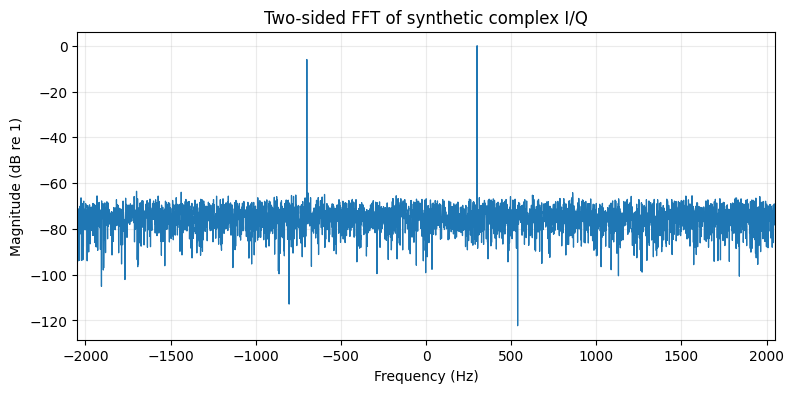

Largest two FFT bins (Hz): [300.0, -700.0]
Saved: /content/drive/MyDrive/Project_AMR_2026/Docs/Stage2_Outputs/iq_fft.png


In [18]:
import matplotlib.pyplot as plt
n = len(iq)
freq = np.fft.fftshift(np.fft.fftfreq(n, d=1.0/fs))
spectrum = np.fft.fftshift(np.fft.fft(iq)) / n
db = 20 * np.log10(np.maximum(np.abs(spectrum), 1e-12))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(freq, db, linewidth=0.9)
ax.set(xlabel="Frequency (Hz)", ylabel="Magnitude (dB re 1)",
       title="Two-sided FFT of synthetic complex I/Q",
       xlim=(-fs/2, fs/2))
ax.grid(alpha=0.25)
out_dir = sample_path.parents[2] / "Docs/Stage2_Outputs"
out_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(out_dir / "iq_fft.png", dpi=160, bbox_inches="tight")
plt.show()
peaks = np.argsort(np.abs(spectrum))[-2:][::-1]
print("Largest two FFT bins (Hz):", freq[peaks].tolist())
print("Saved:", out_dir / "iq_fft.png")

## 5. 将序列变成 STFT 时频图

用另外生成的复数扫频序列演示时频变化：2秒内由约 +200 Hz 上升到 +1000 Hz。这是 CPU 信号处理演示，与上面单独的 GPU 检查区分。

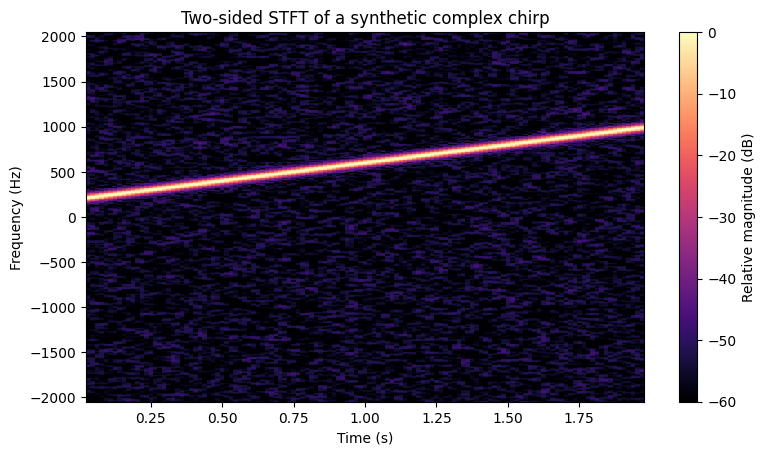

STFT shape (frequency, time): (512, 125)
Saved: /content/drive/MyDrive/Project_AMR_2026/Docs/Stage2_Outputs/stft_spectrogram.png


In [19]:
from scipy.signal import stft
rng = np.random.default_rng(2026)
t = np.arange(8192) / fs
chirp_iq = np.exp(1j * 2*np.pi * (200*t + 0.5*400*t*t))
chirp_iq += 0.015 * (rng.standard_normal(len(t)) +
                    1j*rng.standard_normal(len(t)))
f_stft, t_stft, z = stft(
    chirp_iq, fs=fs, window="hann", nperseg=256, noverlap=192,
    nfft=512, return_onesided=False, boundary=None, padded=False)
f_stft = np.fft.fftshift(f_stft)
z = np.fft.fftshift(z, axes=0)
ref = max(float(np.abs(z).max()), 1e-12)
db_stft = 20*np.log10(np.maximum(np.abs(z)/ref, 1e-12))
fig, ax = plt.subplots(figsize=(9, 4.8))
im = ax.pcolormesh(t_stft, f_stft, db_stft, shading="auto",
                    cmap="magma", vmin=-60, vmax=0)
ax.set(xlabel="Time (s)", ylabel="Frequency (Hz)",
       title="Two-sided STFT of a synthetic complex chirp",
       ylim=(-fs/2, fs/2))
fig.colorbar(im, ax=ax, label="Relative magnitude (dB)")
fig.savefig(out_dir / "stft_spectrogram.png", dpi=160, bbox_inches="tight")
plt.show()
print("STFT shape (frequency, time):", z.shape)
print("Saved:", out_dir / "stft_spectrogram.png")

## 6. 保存自己的结果

1. 保存 Drive 读取和真实 GPU 输出截图。
2. 从 Drive 下载两张结果图到本地仓库 `Docs/Stage2_Outputs/`。
3. 通过“文件 → 下载 → 下载 .ipynb”保存实际运行后的 Notebook，并更新本地 `Notebooks/Stage2_Colab.ipynb`。
4. 截图存入 `Docs/Stage2_Screenshots/`，填写阶段记录，更新 README 后提交 Git。

Colab 的 GPU 成功结果应注明“云端”，不能作为“本地 GPU”截图。